In [1]:
import scanpy as sc
import numpy as np
import random
import sys
sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
query_dataset = "Tata_unpubl"

In [3]:
adata = sc.read_h5ad(f"./scanvi_models/{query_dataset}/emb.h5ad")

### Run MapQC on healthy

In [4]:
n_nhoods = 500
k=1000

In [5]:
ref_q_key = "core_or_extension"
ref_cat = "core"
query_cat = "extension"
condition_key = "lung_condition"
batch_key = "dataset"

In [7]:
adata.obs.loc[adata.obs[ref_q_key] == query_cat, "lung_condition"].unique()

['Healthy']
Categories (2, object): ['Healthy', 'Healthy (tumor adjacent)']

In [8]:
condition_of_interest = "Healthy"
print(f"Subsetting query to condition {condition_of_interest}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest)
].copy()

Subsetting query to condition Healthy


In [9]:
query_cell_idc = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc = random.sample(query_cell_idc, k=n_nhoods)
center_cells = np.array(adata_healthy.obs.iloc[center_cell_idc, :].index)

In [10]:
results = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells,
    k=k,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key="dataset"
)

In [11]:
results.calculate_sample_dists_to_ref_samples()

../../../mapqc/mapqc.py:180: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../mapqc/mapqc.py:184: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [12]:
results.calculate_nhood_statistics()

38% of neighborhoods passed filtering.
19% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


../../../mapqc/mapqc.py:249: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


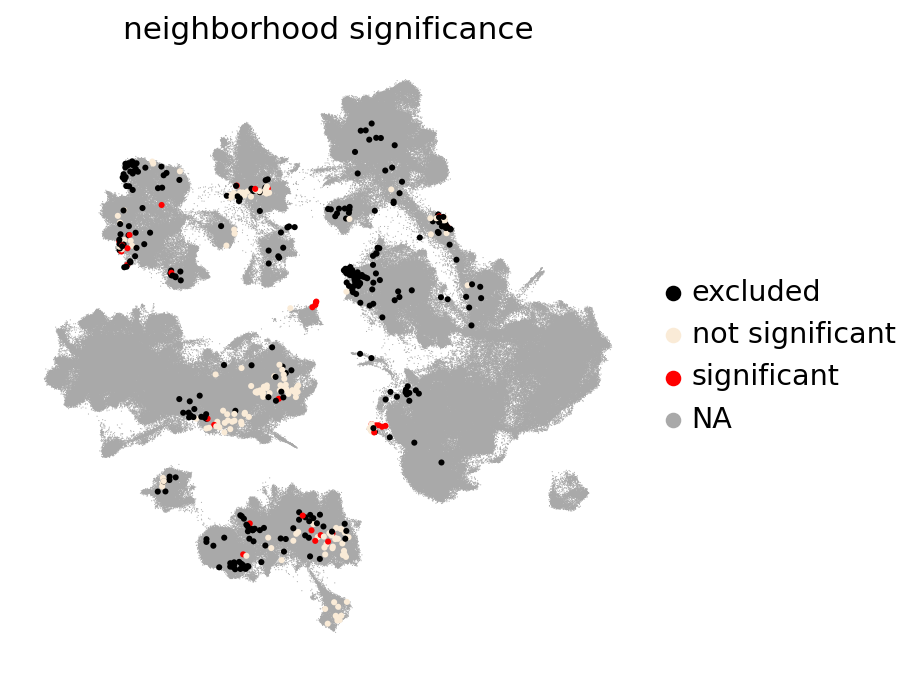

In [13]:
plotting.plot_umap_significance(results)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


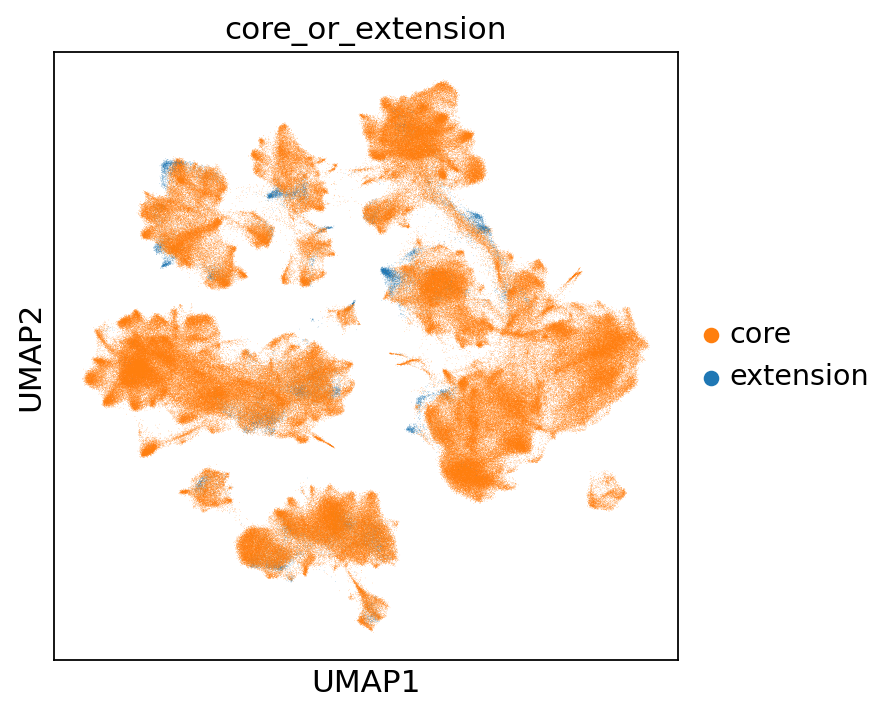

In [15]:
sc.pl.umap(results.adata,color=ref_q_key, palette={ref_cat:"tab:orange",query_cat:"tab:blue"})

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


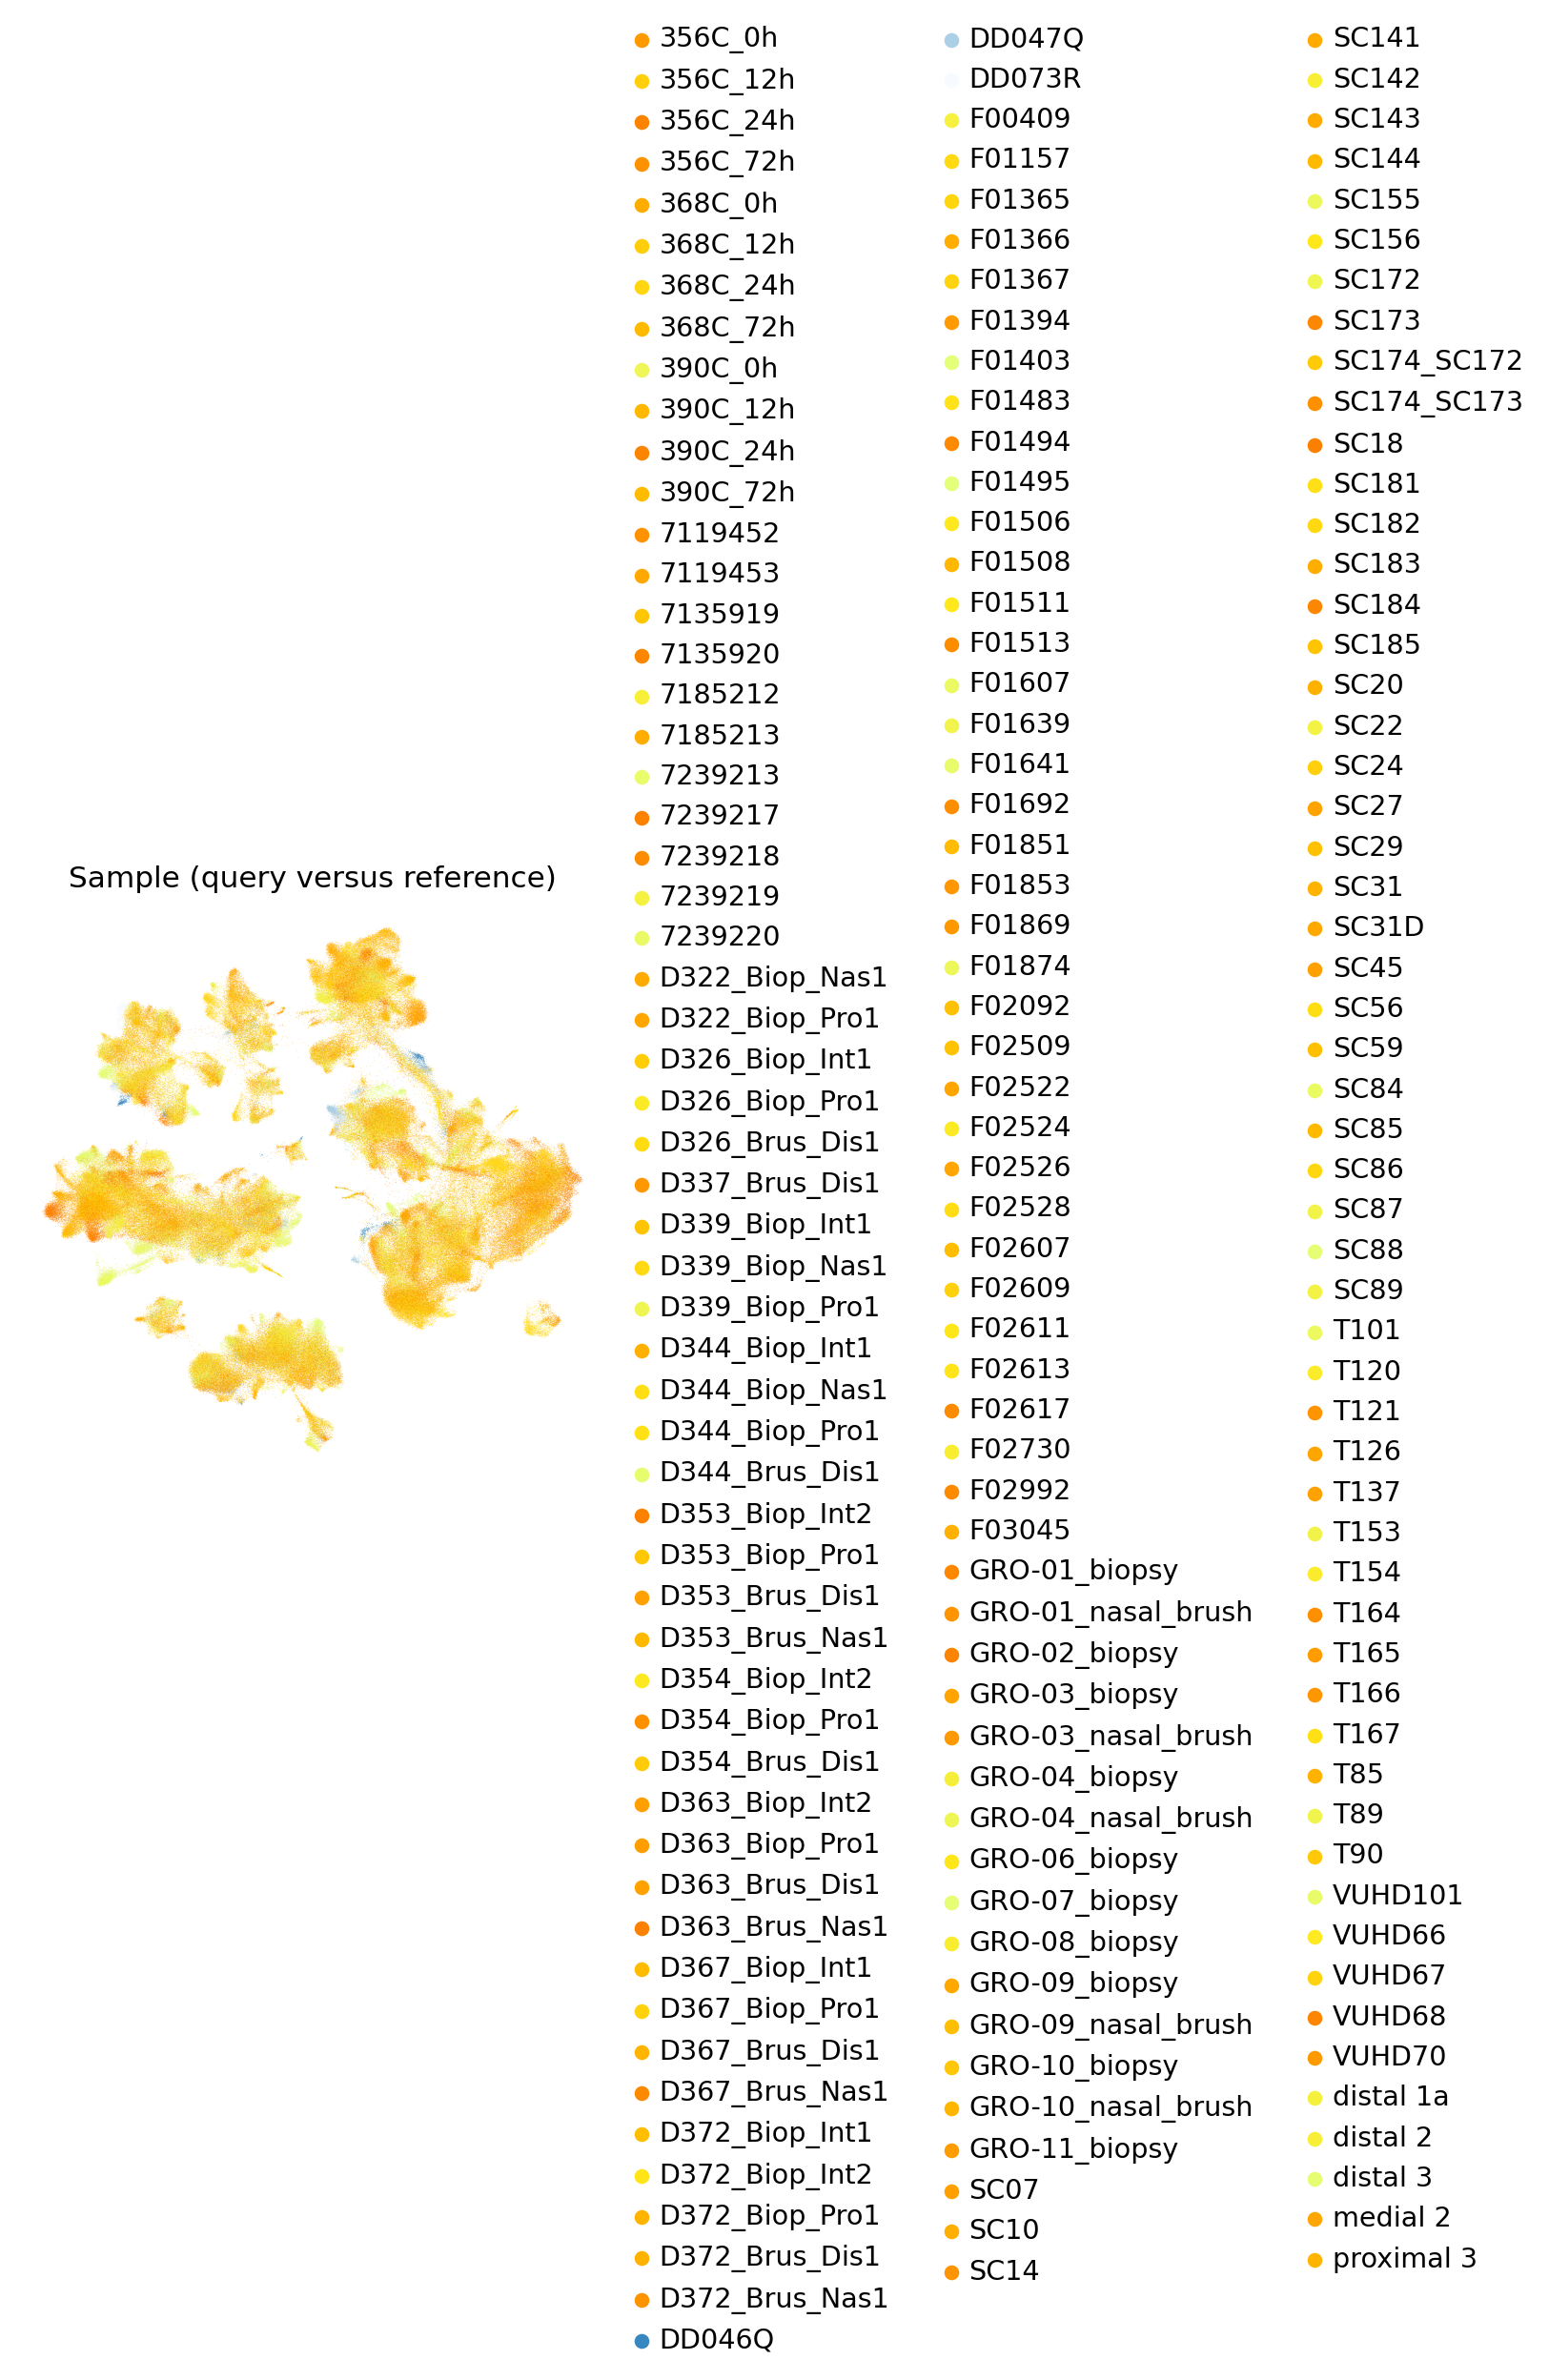

In [16]:
plotting.plot_umap_q_ref_sample_shaded(results,include_legend=True)

In [17]:
adata.obs.loc[adata.obs.dataset == "Tata_unpubl","sample"].unique()

['DD046Q', 'DD047Q', 'DD073R']
Categories (169, object): ['356C_0h', '356C_12h', '356C_24h', '356C_72h', ..., 'distal 2', 'distal 3', 'medial 2', 'proximal 3']

In [20]:
sc.pp.neighbors(adata, n_neighbors=30)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [21]:
sc.tl.umap(adata)

KeyboardInterrupt: 

In [ ]:
adata.write(f"./scanvi_models/{query_dataset}/emb.h5ad")